# Spam Message Classifier

Simple notebook version of the training pipeline: load data, clean text, TF-IDF + Logistic Regression, evaluate.

This mirrors what `src/train.py` does, just in a more exploratory/notebook style.

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## 1. Load the dataset

In [2]:
df = pd.read_csv('../data/spam.csv')
print(df.shape)
df.head()

(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
df['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

The dataset is imbalanced - a lot more 'ham' messages than 'spam'. Worth keeping in mind for evaluation (accuracy alone can be misleading).

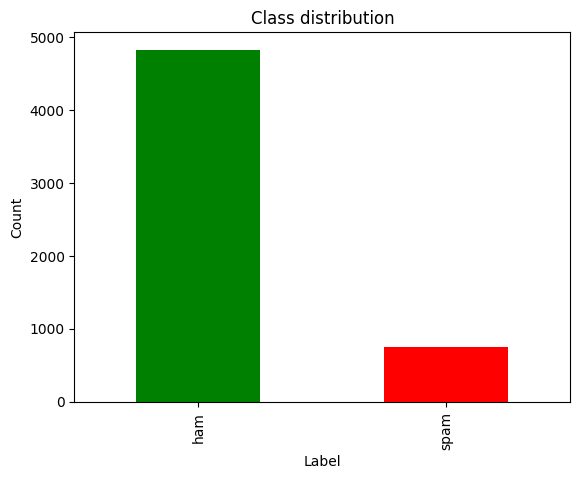

In [4]:
df['label'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Class distribution')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

## 2. Text cleaning\n\nLowercase, remove URLs/HTML/numbers/special characters, tokenize, remove stopwords, lemmatize.

In [5]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 1]
    return ' '.join(tokens)

# quick test
clean_text('Congratulations!! You WON a free prize, call 09061701461 now http://bit.ly/x')

'congratulation free prize call'

In [6]:
df['clean_message'] = df['message'].apply(clean_text)
df = df[df['clean_message'].str.strip() != ''].reset_index(drop=True)
df[['message', 'clean_message']].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis great wo...
1,Ok lar... Joking wif u oni...,ok lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,dun say early hor already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think go usf life around though


## 3. Train/test split + TF-IDF

In [7]:
X = df['clean_message']
y = df['label'].map({'ham': 0, 'spam': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

X_train_tfidf.shape, X_test_tfidf.shape

((4447, 3000), (1112, 3000))

## 4. Train Logistic Regression

In [8]:
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_tfidf, y_train)

preds = model.predict(X_test_tfidf)

print('Accuracy :', accuracy_score(y_test, preds))
print('Precision:', precision_score(y_test, preds))
print('Recall   :', recall_score(y_test, preds))
print('F1-score :', f1_score(y_test, preds))
print()
print(classification_report(y_test, preds, target_names=['ham', 'spam']))

Accuracy : 0.9748201438848921
Precision: 0.9006622516556292
Recall   : 0.912751677852349
F1-score : 0.9066666666666666

              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       963
        spam       0.90      0.91      0.91       149

    accuracy                           0.97      1112
   macro avg       0.94      0.95      0.95      1112
weighted avg       0.97      0.97      0.97      1112



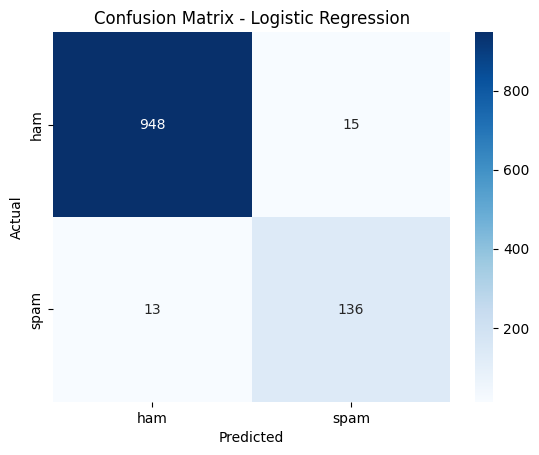

In [9]:
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['ham','spam'], yticklabels=['ham','spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

## 5. Naive Bayes, just for comparison

In [10]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)

print('Accuracy :', accuracy_score(y_test, nb_preds))
print('Precision:', precision_score(y_test, nb_preds))
print('Recall   :', recall_score(y_test, nb_preds))
print('F1-score :', f1_score(y_test, nb_preds))

Accuracy : 0.9766187050359713
Precision: 1.0
Recall   : 0.825503355704698
F1-score : 0.9044117647058824


Naive Bayes gets slightly higher accuracy/precision here but noticeably lower recall - it misses more actual spam messages. Since catching spam matters more than being perfectly precise, and Logistic Regression is easier to explain (coefficients per word), we went with Logistic Regression for the final app.

## 6. Save the model

In [11]:
import joblib
import os

os.makedirs('../models', exist_ok=True)
joblib.dump({'model': model, 'vectorizer': vectorizer}, '../models/spam_classifier.pkl')
print('saved')

saved


## 7. Try it on a few sample messages

In [12]:
samples = [
    'Congratulations! You have won a free prize. Call now!',
    'Hey, are we meeting at 6 pm today?',
    'URGENT! You have been selected for a cash reward. Click this link now.',
    "Can you send me the notes from today's class?"
]

for msg in samples:
    cleaned = clean_text(msg)
    vec = vectorizer.transform([cleaned])
    pred = model.predict(vec)[0]
    prob = model.predict_proba(vec)[0]
    label = 'spam' if pred == 1 else 'ham'
    conf = prob[1] if pred == 1 else prob[0]
    print(f'{msg}\n -> {label} ({conf*100:.1f}% confidence)\n')

Congratulations! You have won a free prize. Call now!
 -> spam (91.6% confidence)

Hey, are we meeting at 6 pm today?
 -> ham (87.4% confidence)

URGENT! You have been selected for a cash reward. Click this link now.
 -> spam (85.5% confidence)

Can you send me the notes from today's class?
 -> ham (83.9% confidence)

